In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import numdifftools as nd
from scipy import stats
from scipy.optimize import minimize
from scipy.optimize import approx_fprime

import importlib
import SyntheticPhaseLinearMeasurement as SPLM
importlib.reload(SPLM)

%config InlineBackend.figure_format = 'retina'
cmap = plt.cm.viridis
rng = np.random.default_rng(seed=326890)   # PCG64 by default

# Model
## Phase drift and diffusion with measurement noise

The latent phase evolves according to the discrete-time stochastic process
\begin{equation}
    \theta_{k+1} = \theta_k + \omega \Delta t + \varepsilon_k, \quad \varepsilon_k \sim \mathcal{N}(0, Q), \quad Q = 2 D_\theta \Delta t
\end{equation}
The measurement model is linear
\begin{equation}
    y_k = \theta_k + \eta_k, \quad \eta_k \sim \mathcal{N}(0,R)
\end{equation}


### Simulated data

We can simulate data from this model as follows.

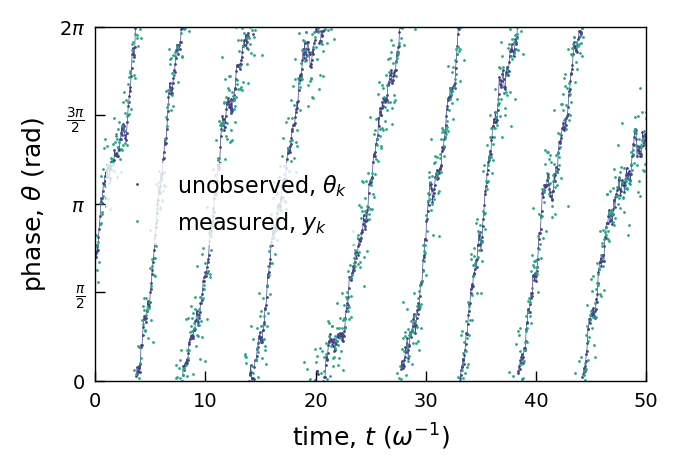

In [4]:
rng = np.random.default_rng(seed=326890)   # PCG64 by default
N = 1000 # number of data points
dt = 0.05 # time step, seconds

omega = 1.   # drift velocity
Dtheta = 0.1 # diffusion coefficient 
R = 0.2   # noise variance, radians^2
param = (omega,Dtheta,R)

mu_theta = 0
sigma_theta = 2*np.pi
state_priors = (mu_theta, sigma_theta)

## Simulate unwrapped phase data
tk, thetak, yk = SPLM.simulate_data(param, N, dt, rng, state_priors)

# detect wrap points
thetak_wrap = np.mod(thetak, 2*np.pi)
dthetak = np.diff(thetak_wrap)
wrap = np.abs(dthetak) > np.pi
thetak_plot = thetak_wrap.copy()
thetak_plot[1:][wrap] = np.nan   # break the line

# Desired axes dimensions in centimeters
axes_width_cm = 7
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
ax.plot(tk, thetak_plot, '-', lw=0.25, color=cmap(0.2))
ax.plot(tk, np.mod(thetak,2*np.pi), '.', ms=2, mew=0, label=r'unobserved, $\theta_k$', color=cmap(0.2))
ax.plot(tk, np.mod(yk,2*np.pi), '.', ms=2, mew=0, label='measured, $y_k$', color=cmap(0.6))

# Set axis labels with font size 9 pt
ax.set_xlabel(r'time, $t$ ($\omega^{-1}$)', fontsize=9)
ax.set_ylabel(r'phase, $\theta$ (rad)', fontsize=9)

# Create legend (frame turned off)
ax.legend(frameon=True, edgecolor='none', fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

ax.set_yticks([0,
               np.pi/2,
               np.pi,
               3*np.pi/2,
               2*np.pi])

ax.set_yticklabels([r'$0$',
                    r'$\frac{\pi}{2}$',
                    r'$\pi$',
                    r'$\frac{3\pi}{2}$',
                    r'$2\pi$'])

# Set the x-axis limits from 0 to 2000
ax.set_xlim(0, N*dt)
ax.set_ylim(0, 2*np.pi)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SyntheticPhaseTrace.pdf')

In [5]:
list_of_tuples = list(zip(tk,yk,thetak))
df = pd.DataFrame(list_of_tuples,
                  columns=['t', 'y', 'theta'])
df

,t,y,theta
0,0.05,-3.873332,-4.006215
1,0.10,-3.686501,-4.078021
2,0.15,-3.873935,-3.987084
3,0.20,-4.319791,-3.891844
4,0.25,-3.818248,-3.956723
...,...,...,...
995,49.80,48.407774,48.175424
996,49.85,48.181653,48.252744
997,49.90,47.832545,48.364670
998,49.95,48.637087,48.294892


In [6]:
df.to_csv('data/simulated_data_SP.csv',index=False)

### Mean squared displacement

The analysis of a diffusing particle is often characterized by the [mean squared displacement](https://en.wikipedia.org/wiki/Mean_squared_displacement) (MSD) of the particle position as a function of the lag time $\tau_n = n\Delta t$.  The MSD is defined as follows

$$ \text{msd} = \langle \Delta \theta^2_n\rangle = \frac{1}{N-n} \sum_{k=1}^{N-n} \left[\theta(t_{k+n}) - \theta(t_k)\right]^2  $$


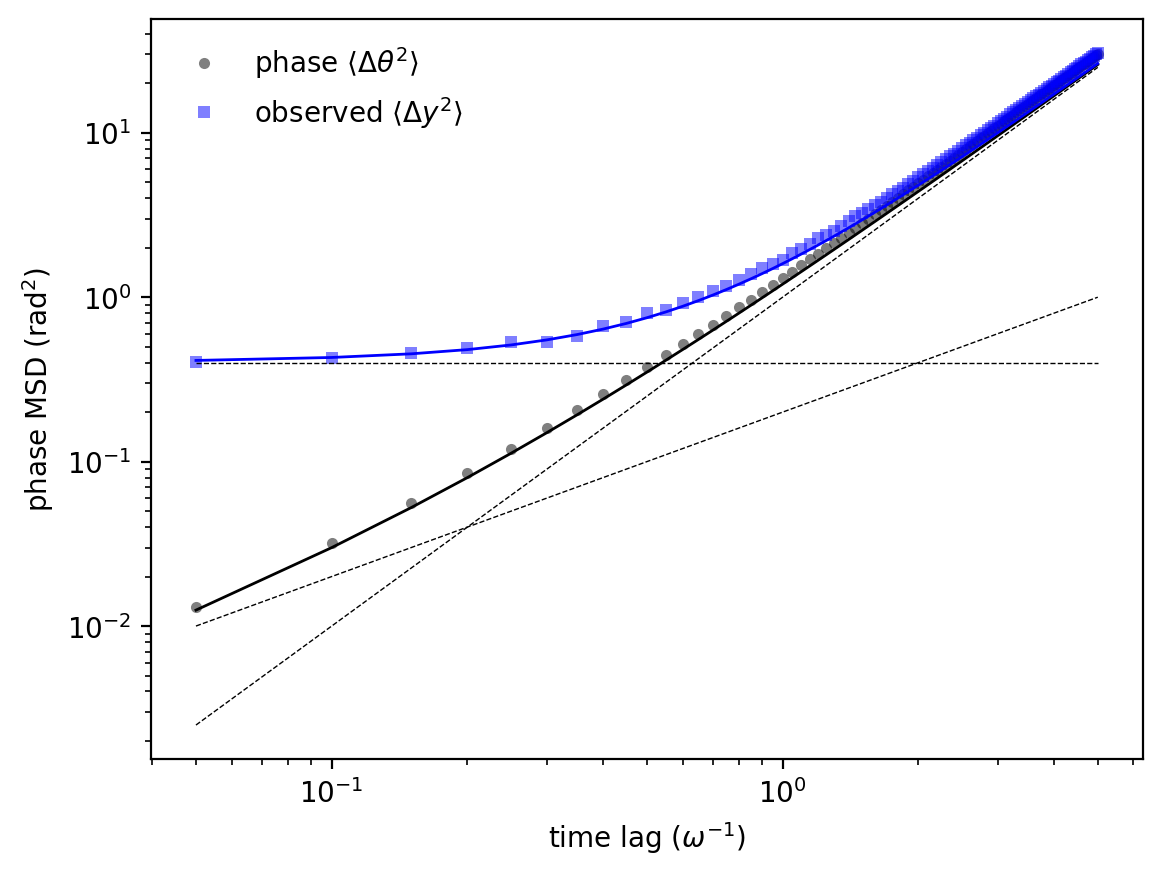

In [7]:
lags = 1+np.arange(100)

# non-overlapping intervals
theta_msds = np.zeros(lags.shape)
y_msds = np.zeros(lags.shape)

# overlapping intervals
theta_msds_ol = np.zeros(lags.shape)  
y_msds_ol = np.zeros(lags.shape) 

for i,lag in enumerate(lags):
    # non-overlapping
    theta_msds[i] = np.mean((thetak[lag::lag] - thetak[:-lag:lag])**2)  
    y_msds[i] = np.mean((yk[lag::lag] - yk[:-lag:lag])**2)

    # overlapping
    theta_msds_ol[i] = np.mean((thetak[lag:] - thetak[:-lag])**2)       
    y_msds_ol[i] = np.mean((yk[lag:] - yk[:-lag])**2)

# plt.loglog(dt*lags, theta_msds, 'ko', mew=0, ms=4, alpha=0.5, label=r'phase $\langle \Delta \theta^2 \rangle$')
plt.loglog(dt*lags, theta_msds_ol, 'ko', mew=0, ms=4, alpha=0.5, label=r'phase $\langle \Delta \theta^2 \rangle$')
plt.plot(dt*lags, 2*Dtheta*dt*lags + (omega*dt*lags)**2, 'k-', lw=1)

# plt.plot(dt*lags, y_msds, 'bs',  mew=0,ms=4, alpha=0.5,  label=r'observed $\langle \Delta y^2 \rangle$')
plt.plot(dt*lags, y_msds_ol, 'bs',  mew=0,ms=4, alpha=0.5,  label=r'observed $\langle \Delta y^2 \rangle$')
plt.plot(dt*lags, 2*R + 2*Dtheta*dt*lags + (omega*dt*lags)**2, 'b-', lw=1)

# theoretical result
plt.plot(dt*lags, 2*Dtheta*dt*lags, 'k--', lw=0.5)
plt.plot(dt*lags, (omega*dt*lags)**2, 'k--', lw=0.5)
plt.plot(dt*lags, 2*R*lags**0, 'k--', lw=0.5)

plt.ylabel(r'phase MSD (rad$^2$)')
plt.xlabel(r'time lag ($\omega^{-1}$)')
plt.legend(frameon=False);

#  Estimating latent phase, $p(\theta_{1:N} \mid y_{1:N}, \lambda)$

Given the parameters $\lambda=\{\theta_0, \omega,  D_\theta, R\}$ and the observed data $y_{1:N}=\{y_1,\dots,y_N\}$, we seek to infer the phase $\theta_{1:N}=\{\theta_1,\dots,\theta_N\}$ using a [Kalman filter](https://en.wikipedia.org/wiki/Kalman_filter)<sup id="fn1">[1](#f1)</sup> with Rauch-Tung-Striebel smoothing.<sup id="fn2">[2](#f2)</sup> This algorithm provides an efficient approach that scales linearly with the number of time steps $N$.

<p id="f1"><b>[1]</b> Kalman, R. E. (1960). "A New Approach to Linear Filtering and Prediction Problems". Journal of Basic Engineering. 82: 35–45. doi:10.1115/1.3662552.</p>
<p id="f2"><b>[2]</b> Rauch, H.E.; Tung, F.; Striebel, C. T. (August 1965). "Maximum likelihood estimates of linear dynamic systems". AIAA Journal. 3 (8): 1445–1450. doi:10.2514/3.3166.</p>


### Priors $p(\lambda)$

\begin{equation}
\begin{aligned}
    \theta_0 &\sim \mathcal{N}( \mu_\theta, \sigma^2_\theta )
    \\
    \omega &\sim \mathcal{N}( \mu_\omega, \sigma^2_\omega )
\end{aligned}
\qquad
\begin{aligned}
    D_\theta &\sim \mathrm{Inv\text{-}Gamma}(\alpha_D, \beta_D)
    \\
    R &\sim \mathrm{Inv\text{-}Gamma}(\alpha_R, \beta_R)
\end{aligned}
\end{equation}

In [8]:
# parameter priors 
mu_omega = omega
sigma_omega = omega
alpha_D = 1
beta_D = 1
alpha_R = 1
beta_R = 1

param_priors = (mu_omega, sigma_omega, alpha_D, beta_D, alpha_R, beta_R)
priors = state_priors + param_priors

## Forward Kalman Filter

In [9]:
# Kalman filter
param = (omega, Dtheta, R)
data = (tk, yk)
thetakk, Pkk, thetakk_1, Pkk_1 = SPLM.kalman_filter(param, data, state_priors)

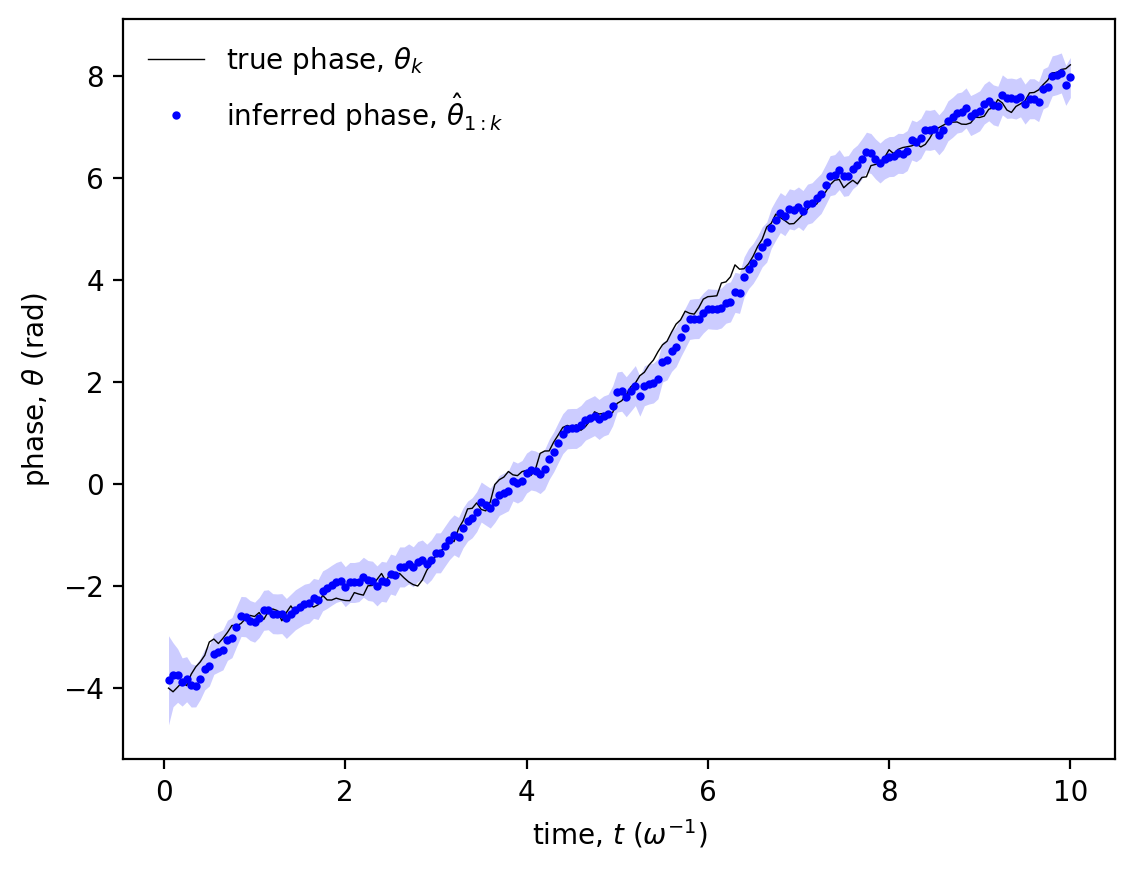

In [10]:
kmax = 200
plt.plot(tk[:kmax], thetak[:kmax], '-', c='k', lw=0.5, label=r'true phase, $\theta_k$')
plt.plot(tk[:kmax], thetakk[:kmax], '.', c='b', ms=4, label=r'inferred phase, $\hat{\theta}_{1:k}$')
plt.fill_between(tk[:kmax], thetakk[:kmax] + 1.96*np.sqrt(Pkk[:kmax]), thetakk[:kmax] - 1.96*np.sqrt(Pkk[:kmax]), 
                 color='b', alpha=0.2, lw=0);

plt.xlabel(r'time, $t$ ($\omega^{-1}$)')
plt.ylabel(r'phase, $\theta$ (rad)')
plt.legend(frameon=False);

We can compute $\log p(y_{1:N}\mid \lambda)$ from the Kalman filter.

In [11]:
nlml = SPLM.neg_log_marginal_likelihood(param, data, state_priors, param_mode="natural")
print(f'Negative log marginal likelihood: {nlml:.5}')

log_param = (omega, np.log(Dtheta), np.log(R))
nlml = SPLM.neg_log_marginal_likelihood(log_param, data, state_priors, param_mode="log")
print(f'Negative log marginal likelihood: {nlml:.5}')

Negative log marginal likelihood: 725.99
Negative log marginal likelihood: 725.99


## Backward Rauch-Tung-Striebel (RTS) Smoother

In [12]:
kalman_phases = (thetakk, Pkk, thetakk_1, Pkk_1)
thetakN, PkN, Sigmakk_1 = SPLM.rts_smoother(param, data, kalman_phases)

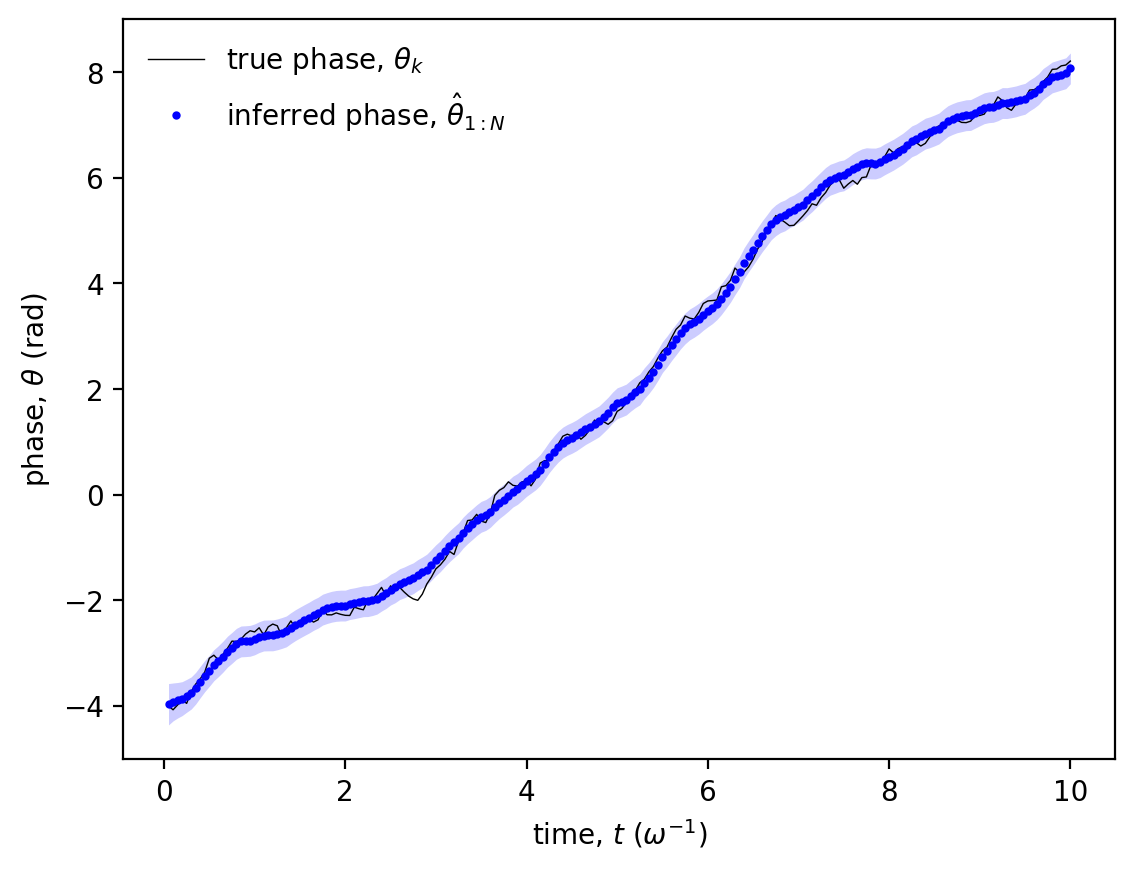

In [13]:
kmax = 200
plt.plot(tk[:kmax], thetak[:kmax], '-', c='k', lw=0.5, label=r'true phase, $\theta_k$')
plt.plot(tk[:kmax], thetakN[:kmax], '.', c='b', ms=4, label=r'inferred phase, $\hat{\theta}_{1:N}$')
plt.fill_between(tk[:kmax], thetakN[:kmax] + 1.96*np.sqrt(PkN[:kmax]), thetakN[:kmax] - 1.96*np.sqrt(PkN[:kmax]), 
                 color='b', alpha=0.2, lw=0);

plt.xlabel(r'time, $t$ ($\omega^{-1}$)')
plt.ylabel(r'phase, $\theta$ (rad)')
plt.legend(frameon=False);

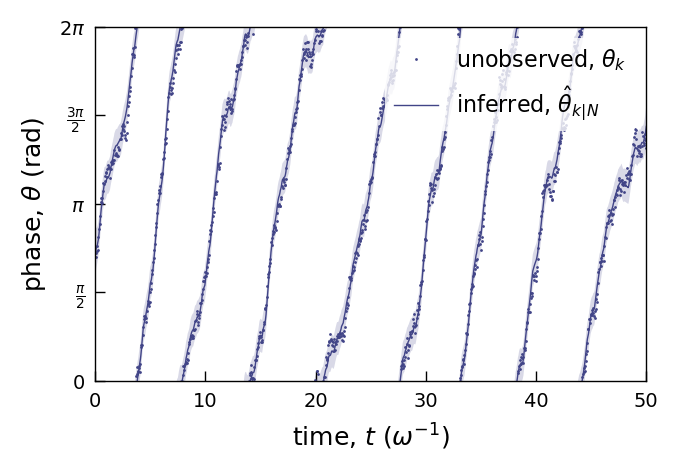

In [14]:
# Desired axes dimensions in centimeters
axes_width_cm = 7
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
ax.plot(tk, np.mod(thetak, 2*np.pi), '.', ms=2, mew=0, label=r'unobserved, $\theta_k$', color=cmap(0.2))
ax.plot(tk, thetakN + 2*np.pi, '-', lw=0.5, label=r'inferred, $\hat{\theta}_{k|N}$', color=cmap(0.2))

thetakN_upper = thetakN + 1.96*np.sqrt(PkN)
thetakN_lower = thetakN - 1.96*np.sqrt(PkN)
ax.fill_between(tk, thetakN_upper + 2*np.pi, thetakN_lower + 2*np.pi, color=cmap(0.2), alpha=0.2, lw=0);

for i in range(0,8):
    ax.plot(tk, thetakN - i*2*np.pi, '-', lw=0.5, color=cmap(0.2))
    ax.fill_between(tk, thetakN_upper - i*2*np.pi, thetakN_lower - i*2*np.pi, color=cmap(0.2), alpha=0.2, lw=0);


# Set axis labels with font size 9 pt
ax.set_xlabel(r'time, $t$ ($\omega^{-1}$)', fontsize=9)
ax.set_ylabel(r'phase, $\theta$ (rad)', fontsize=9)

# Create legend (frame turned off)
ax.legend(frameon=True, fontsize=8, edgecolor='none', loc=1)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

ax.set_yticks([0,
               np.pi/2,
               np.pi,
               3*np.pi/2,
               2*np.pi])

ax.set_yticklabels([r'$0$',
                    r'$\frac{\pi}{2}$',
                    r'$\pi$',
                    r'$\frac{3\pi}{2}$',
                    r'$2\pi$'])

ax.set_xlim(0, N*dt)
ax.set_ylim(0, 2*np.pi)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SyntheticPhaseTrace_Inferred.pdf')

## Mean Squared Displacement (revisited)

In [15]:
# Solve Ax = rhs
Sigma = SPLM.theta_covariance(param, N, dt, state_priors)

The diagonal entries are the same as those obtained from the Kalman filter above.

In [16]:
error = np.array([np.linalg.norm(Sigma[k,k] - PkN[k]) for k in range(N)])
print(error.mean())

1.3399004128444858e-17


We can compute the relevant elements in a more efficient way as follows.

In [17]:
error = np.array([(Sigma[k,k-1]-Sigmakk_1[k]) for k in range(1,N)])
print(error.mean())

9.606096365469166e-18


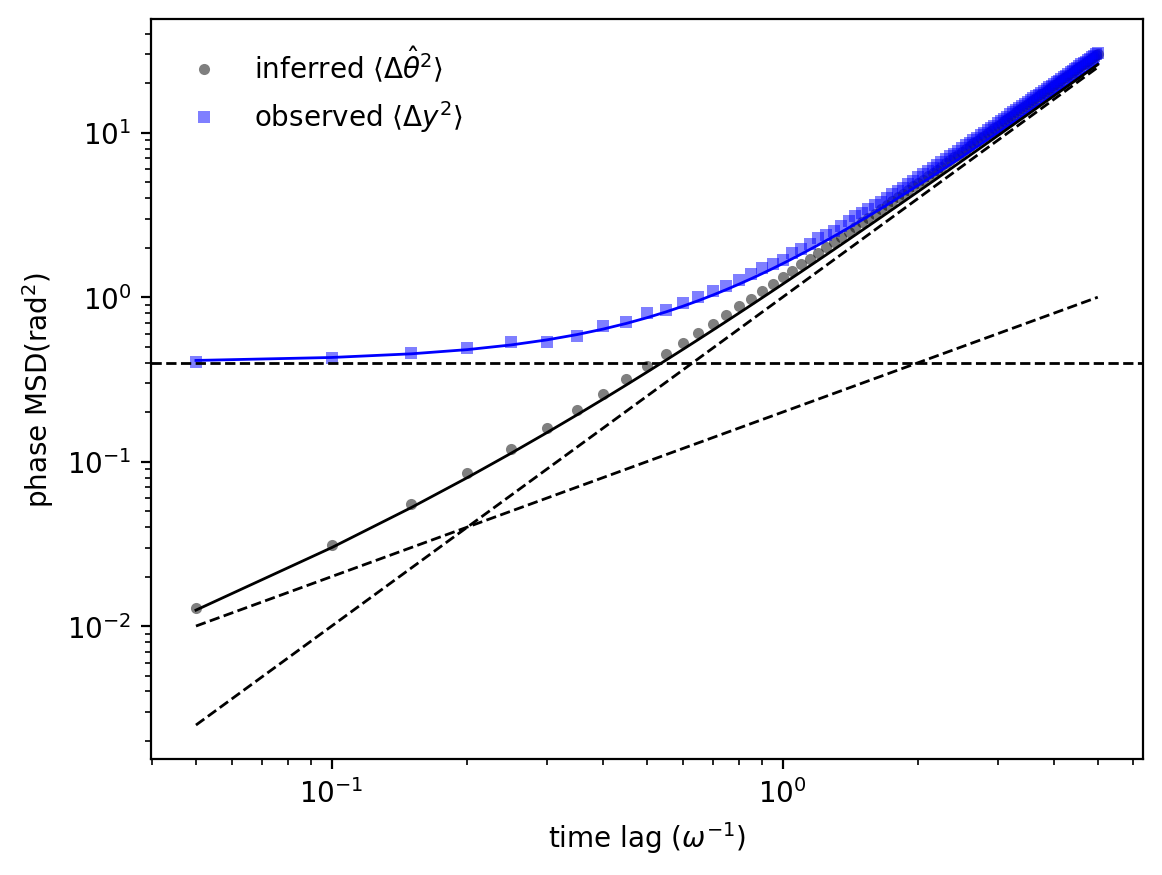

In [18]:
lags = 1+np.arange(100)
thetahat_msds = np.zeros(lags.shape)     # non-overlapping
thetahat_msds_ol = np.zeros(lags.shape)  # overlapping

for i,lag in enumerate(lags):
    thetahat_msds[i] = np.mean((thetakN[lag::lag] - thetakN[:-lag:lag])**2 + np.diag(Sigma)[lag::lag] + np.diag(Sigma)[:-lag:lag]
                           - 2*np.diag(Sigma,k=lag)[::lag])  # non-overlapping
    thetahat_msds_ol[i] = np.mean((thetakN[lag:] - thetakN[:-lag])**2 + np.diag(Sigma)[lag:] + np.diag(Sigma)[:-lag]
                           - 2*np.diag(Sigma,k=lag))         # overlapping
    
# plt.loglog(dt*lags, thetahat_msds, 'ko', mew=0, ms=4, alpha=0.5, label=r'inferred $\langle \Delta x^2 \rangle$')
plt.loglog(dt*lags, thetahat_msds_ol, 'ko', mew=0, ms=4, alpha=0.5, label=r'inferred $\langle \Delta \hat{\theta}^2 \rangle$')

# plt.plot(dt*lags, y_msds, 'bs',  mew=0,ms=4, alpha=0.5,  label=r'observed $\langle \Delta y^2 \rangle$')
plt.plot(dt*lags, y_msds_ol, 'bs',  mew=0,ms=4, alpha=0.5,  label=r'observed $\langle \Delta y^2 \rangle$')

plt.plot(dt * lags, 2*R + 2 * Dtheta * dt * lags + (omega * dt * lags)**2, 'b-', lw=1)
plt.plot(dt * lags, 2 * Dtheta * dt * lags + (omega * dt * lags)**2, 'k-', lw=1)
plt.plot(dt * lags, (omega * dt * lags)**2, 'k--', lw=1)
plt.plot(dt * lags, 2 * Dtheta * dt * lags, 'k--', lw=1)

plt.axhline(y=2*R, color='k', ls='--', lw=1)
plt.ylabel(r'phase MSD(rad$^2$)')
plt.xlabel(r'time lag ($\omega^{-1}$)')
plt.legend(frameon=False);

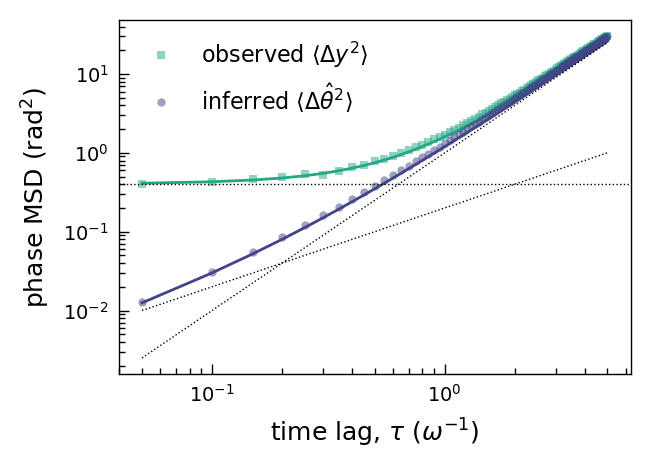

In [19]:
# Desired axes dimensions in centimeters
axes_width_cm = 6.5
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
# ax.plot(dt*lags, y_msds, 's',  mew=0,ms=3, alpha=0.5,  color=cmap(0.6),
#         label=r'observed $\langle \Delta y^2 \rangle$')
ax.plot(dt*lags, y_msds_ol,  's',  mew=0,ms=3, alpha=0.5,  color=cmap(0.6),
        label=r'observed $\langle \Delta y^2 \rangle$')
ax.plot(dt*lags, 2*R + 2*Dtheta*dt*lags +  (omega*dt*lags)**2, '-', lw=1, color=cmap(0.6))

# ax.loglog(dt*lags, thetahat_msds, 'o', mew=0, ms=3, color=cmap(0.2), alpha=0.5, 
# label=r'inferred $\langle \Delta \hat{\theta}^2 \rangle$')
ax.loglog(dt*lags, thetahat_msds_ol,  'o', mew=0, ms=3, color=cmap(0.2), alpha=0.5, 
          label=r'inferred $\langle \Delta \hat{\theta}^2 \rangle$')
ax.plot(dt*lags, 2*Dtheta*dt*lags +  (omega*dt*lags)**2, '-', lw=1, color=cmap(0.2))

# Theory
ax.plot(dt*lags, (omega*dt*lags)**2, 'k:', lw=0.5)
ax.plot(dt*lags, 2*Dtheta*dt*lags, 'k:', lw=0.5)
plt.axhline(y = 2*R,  ls=':', color='k', lw=0.5)

# Set axis labels with font size 9 pt
ax.set_xlabel(r'time lag, $\tau$ ($\omega^{-1}$)', fontsize=9)
ax.set_ylabel(r'phase MSD (rad$^2$)', fontsize=9)

# Create legend (frame turned off)
ax.legend(frameon=False, fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SyntheticPhaseMSD.pdf')

# Estimating parameters, $p(\lambda \mid y_{1:N})$

## Optimization of $\log p(\lambda \mid y)$ 

### Gradient-free optimizer

We can optimize $-\log p(\lambda\mid y)$ directly using a gradient free optimizer like Powell or Nelder-Mead.

In [20]:
%%time

res = minimize(
    fun=lambda x: SPLM.neg_log_posterior(x, data, priors, param_mode="log"),
    x0=log_param,
    method="Powell")

lambda_map = res.x
print(res,'\n')

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 735.1745087616922
       x: [ 1.051e+00 -2.008e+00 -1.631e+00]
     nit: 2
   direc: [[ 1.000e+00  0.000e+00  0.000e+00]
           [ 0.000e+00  1.000e+00  0.000e+00]
           [ 0.000e+00  0.000e+00  1.000e+00]]
    nfev: 56 

CPU times: user 64.3 ms, sys: 3.05 ms, total: 67.3 ms
Wall time: 69.3 ms


### Finite difference hessian

In [21]:
%%time

## Compute the hessian matrix
f = lambda x: SPLM.neg_log_posterior(x, data, priors, param_mode="log")
hessFunc = nd.Hessian(f)
lambda_hess = hessFunc(lambda_map)
lambda_cov = np.linalg.inv(lambda_hess)

## Print parameter estimates
print(f'omega\t= {lambda_map[0]:.5f} +/- {np.sqrt(lambda_cov[0,0]):.5f}' )
print(f'Dtheta\t= {np.exp(lambda_map[1]):.5f} * exp(+/- {np.sqrt(lambda_cov[1,1]):.5f})' )
print(f'R\t= {np.exp(lambda_map[2]):.5f} * exp(+/- {np.sqrt(lambda_cov[2,2]):.5f})\n' )

omega	= 1.05053 +/- 0.07335
Dtheta	= 0.13420 * exp(+/- 0.16771)
R	= 0.19579 * exp(+/- 0.05086)

CPU times: user 222 ms, sys: 4.38 ms, total: 226 ms
Wall time: 231 ms


### Marginal Distributions

z-score: 0.68881


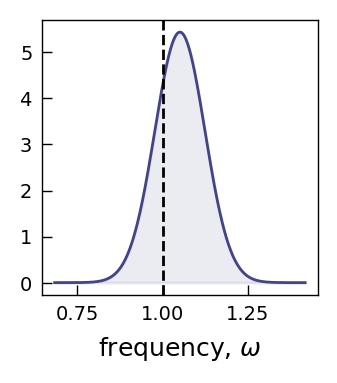

In [22]:
omega_map = lambda_map[0]
omega_err = np.sqrt(lambda_cov[0,0])
print(f'z-score: {(omega_map-omega)/omega_err:.5}')

omegas = np.linspace(omega_map-5*omega_err, omega_map+5*omega_err, 500)
pdf = stats.norm.pdf(omegas, loc=omega_map, scale=omega_err)

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(omegas,pdf,color=cmap(0.2), label='true', lw=1)
plt.fill_between(omegas,pdf,alpha=0.1,color=cmap(0.2))

plt.axvline(x=omega, color='k', ls='--', lw=1, label='True value')

# Set axis labels with font size 9 pt
ax.set_xlabel(r'frequency, $\omega$', fontsize=9)

# Create legend (frame turned off)
# ax.legend(frameon=False, fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('SP_Frequency.pdf')

z-score: 1.7541
1.000001308910812


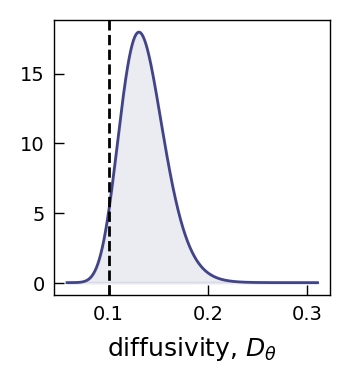

In [23]:
lnDtheta_map = lambda_map[1]
lnDtheta_err = np.sqrt(lambda_cov[1,1])
print(f'z-score: {(lnDtheta_map-np.log(Dtheta))/lnDtheta_err:.5}')

lnDthetas = np.linspace(lnDtheta_map-5*lnDtheta_err, lnDtheta_map+5*lnDtheta_err, 500)
Dthetas = np.exp(lnDthetas)
pdf = stats.lognorm.pdf(Dthetas, s=lnDtheta_err, scale=np.exp(lnDtheta_map))
print(np.trapezoid(pdf, Dthetas))

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(Dthetas,pdf,color=cmap(0.2), label='true', lw=1)
plt.fill_between(Dthetas,pdf,alpha=0.1,color=cmap(0.2))

plt.axvline(x=Dtheta, color='k', ls='--', lw=1, label='True value')

# Set axis labels with font size 9 pt
ax.set_xlabel(r'diffusivity, $D_\theta$', fontsize=9)
# ax.set_xscale('log')

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SP_Diffusivity.pdf')

z-score: -0.41832
0.9999995993705184


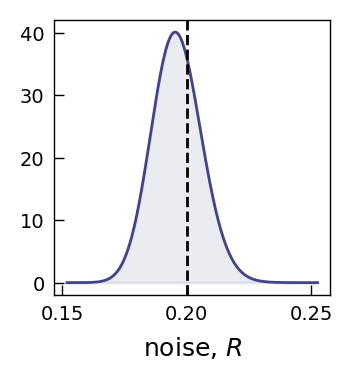

In [27]:
lnR_map = lambda_map[2]
lnR_err = np.sqrt(lambda_cov[2,2])
print(f'z-score: {(lnR_map-np.log(R))/lnR_err:.5}')

lnRs = np.linspace(lnR_map-5*lnR_err, lnR_map+5*lnR_err, 500)
Rs = np.exp(lnRs)
pdf = stats.lognorm.pdf(Rs, s=lnR_err, scale=np.exp(lnR_map))
print(np.trapezoid(pdf, Rs))

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(Rs,pdf,color=cmap(0.2), label='true', lw=1)
plt.fill_between(Rs,pdf,alpha=0.1,color=cmap(0.2))

plt.axvline(x=R, color='k', ls='--', lw=1, label='True value')

# Set axis labels with font size 9 pt
ax.set_xlabel(r'noise, $R$', fontsize=9)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SP_Noise.pdf')

1.0000007351094284
0.9999988523990652


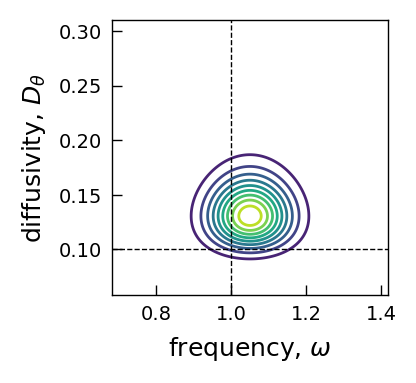

In [28]:
OMEGAS, LNDTHETAS = np.meshgrid(omegas, lnDthetas)

pos = np.dstack((OMEGAS, LNDTHETAS))
DTHETAS = np.exp(LNDTHETAS)

# evaluate pdf
rv = stats.multivariate_normal(np.array([omega_map, lnDtheta_map]), lambda_cov[0:2,0:2])
Z = rv.pdf(pos)
print(np.trapezoid(np.trapezoid(Z / DTHETAS, omegas), Dthetas))
print(np.trapezoid(np.trapezoid(Z, omegas), lnDthetas))

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# plot
plt.contour(OMEGAS, DTHETAS, Z / DTHETAS, levels=10, linewidths=1)
plt.axhline(y=Dtheta, color='k', ls='--', lw=0.5)
plt.axvline(x=omega, color='k', ls='--', lw=0.5)

# Set axis labels with font size 9 pt
plt.xlabel(r"frequency, $\omega$", fontsize=9)
plt.ylabel(r"diffusivity, $D_\theta$", fontsize=9)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SP_Frequency_Diffusivity.pdf')

0.9999990255701166
0.9999988523990659


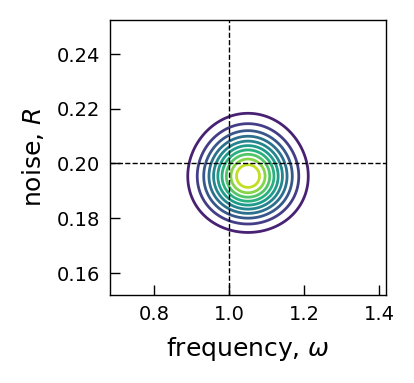

In [31]:
OMEGAS, LNRS = np.meshgrid(omegas, lnRs)

pos = np.dstack((OMEGAS, LNRS))
RS = np.exp(LNRS)

# evaluate pdf
rv = stats.multivariate_normal(np.array([omega_map, lnR_map]), 
                               lambda_cov[np.ix_([0,2], [0,2])])
Z = rv.pdf(pos)
print(np.trapezoid(np.trapezoid(Z / RS, omegas), Rs))
print(np.trapezoid(np.trapezoid(Z, omegas), lnRs))

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# plot
plt.contour(OMEGAS, RS, Z/RS, levels=10, linewidths=1)
plt.axhline(y=R, color='k', ls='--', lw=0.5)
plt.axvline(x=omega, color='k', ls='--', lw=0.5)

plt.xlabel(r"frequency, $\omega$", fontsize=9)
plt.ylabel(r"noise, $R$", fontsize=9)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SP_Frequency_Noise.pdf')

1.0000009083061436
0.9999988524244037


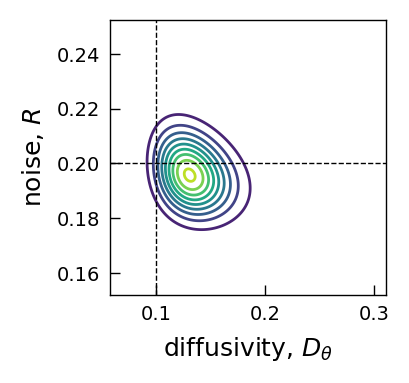

In [30]:
LNDTHETAS, LNRS = np.meshgrid(lnDthetas, lnRs)

pos = np.dstack((LNDTHETAS, LNRS))
DTHETAS = np.exp(LNDTHETAS)
RS = np.exp(LNRS)

# evaluate pdf
rv = stats.multivariate_normal(np.array([lnDtheta_map, lnR_map]), lambda_cov[1:,1:])
Z = rv.pdf(pos)
print(np.trapezoid(np.trapezoid(Z / DTHETAS / RS, Dthetas), Rs))
print(np.trapezoid(np.trapezoid(Z, lnDthetas), lnRs))

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# plot
plt.contour(DTHETAS, RS, Z / DTHETAS / RS, levels=10, linewidths=1)
plt.axhline(y=R, color='k', ls='--', lw=0.5)
plt.axvline(x=Dtheta, color='k', ls='--', lw=0.5)

plt.xlabel(r"diffusivity, $D_\theta$", fontsize=9);
plt.ylabel(r"noise, $R$", fontsize=9)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SP_Diffusivity_Noise.pdf')

### Gradient-based optimizer

\begin{equation}
    \nabla_\lambda \log p(y\mid \lambda) = \mathbb{E}[\nabla_\lambda \ell_c(\lambda; \theta, y) \mid y,\lambda]
\end{equation}

Complete-data log likelihood $\ell_c(\lambda; \theta, y) = \ln p(\theta, y\mid \lambda)$ is given by 

$$ \ell_c(\lambda; \theta, y)  = \text{const.} - \tfrac{1}{2} (N-1) \ln D_\theta - \frac{1}{4 D_\theta \Delta t} \sum_{k=2}^{N} (\theta_{k} - \theta_{k-1} - \omega \Delta t)^2 - \tfrac{1}{2} N \ln R - \frac{1}{2 R} \sum_{k=1}^N (y_k - \theta_{k})^2 $$

In [32]:
%%time

res = minimize(
    fun=lambda x: SPLM.neg_log_posterior(x, data, priors, param_mode="log"),
    x0=(omega, np.log(Dtheta), np.log(R)),
    jac=lambda x: SPLM.grad_neg_log_posterior(x, data, priors, param_mode="log"),
    method="L-BFGS-B"
)

lambda_map2 = res.x
print(res,'\n')

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 735.1745011144882
        x: [ 1.051e+00 -2.008e+00 -1.631e+00]
      nit: 7
      jac: [ 4.942e-04  3.990e-04  1.756e-04]
     nfev: 10
     njev: 10
 hess_inv: <3x3 LbfgsInvHessProduct with dtype=float64> 

CPU times: user 47.4 ms, sys: 6.22 ms, total: 53.6 ms
Wall time: 55.5 ms


Compare to previous solution.

In [33]:
print(lambda_map)
print(lambda_map2)
print(lambda_map - lambda_map2)

[ 1.05052678 -2.0083969  -1.63071568]
[ 1.05052333 -2.00773017 -1.63076398]
[ 3.44469627e-06 -6.66728314e-04  4.83019964e-05]


Compare to numerical derivative.

In [34]:
eps = 1e-6
g_log_fd = approx_fprime(lambda_map2, lambda x: SPLM.neg_log_posterior(x, data, priors, param_mode="log"), epsilon=eps)
g_log_an = SPLM.grad_neg_log_posterior(lambda_map2, data, priors, param_mode="log")
print(g_log_fd)
print(g_log_an)

[0.00058583 0.00041757 0.00037744]
[0.00049415 0.00039901 0.0001756 ]


The natural parameterization posterior $p_{\text{nat}}(\lambda\mid y)$ with $\lambda = \{\omega, D_\theta, R\}$ is related to the log parameterization posterior $p_{\log}(\tilde{\lambda}\mid y)$ with $\tilde{\lambda} = \{\omega, \log D_\theta, \log R\}$ as 

$$ p_{\text{nat}}(\lambda\mid y) = p_{\log}(\tilde{\lambda}\mid y)  \lvert J \rvert \quad \text{with} \quad J =\frac{\partial \tilde{\lambda}}{\partial \lambda} =  \frac{1}{D_\theta R} $$

The gradients are related as 

$$ 
\nabla_\lambda \log p_{\text{nat}}(\lambda\mid y) = \nabla_\lambda [\log p_{\log}(\tilde{\lambda}\mid y) - \log D_\theta - \log R]$$

$$ 
\nabla_\lambda \log p_{\text{nat}}(\lambda\mid y) = J^T \nabla_{\tilde{\lambda}}   \log p_{\log}(\tilde{\lambda}\mid y) - \begin{pmatrix} 0 \\ \frac{1}{D_\theta} \\  \frac{1}{R} \end{pmatrix} $$

In [35]:
eps = 1e-6
param = (lambda_map2[0], np.exp(lambda_map2[1]), np.exp(lambda_map2[2]))
g_fd = approx_fprime(param, lambda x: SPLM.neg_log_posterior(x, data, priors, param_mode="natural"), epsilon=eps)
g_an = SPLM.grad_neg_log_posterior(param, data, priors, param_mode="natural")

vec = np.array([0, np.exp(-lambda_map2[1]), np.exp(-lambda_map2[2])])
print(g_fd - vec)
print(g_an - vec)

[0.00058583 0.00398193 0.0062016 ]
[0.00049415 0.00297118 0.00089692]


In [36]:
param = (omega, Dtheta, R)
log_param = (omega, np.log(Dtheta), np.log(R))

eps = 1e-6
g_fd = approx_fprime(param, lambda x: SPLM.neg_log_posterior(x, data, priors, param_mode="natural"), epsilon=eps)
g_an = SPLM.grad_neg_log_posterior(param, data, priors, param_mode="natural")
g_log_fd = approx_fprime(log_param, lambda x: SPLM.neg_log_posterior(x, data, priors, param_mode="log"), epsilon=eps)
g_log_an = SPLM.grad_neg_log_posterior(log_param, data, priors, param_mode="log")

vec = np.array([0, 1/Dtheta, 1/R])
J = np.diag(vec)
J[0,0] = 1
print(g_fd)
print(g_an)
print(J@g_log_fd + vec)
print(J@g_log_an + vec)

[ -12.59949056 -101.66067875    8.55791143]
[ -12.5996136  -101.66321573    8.55271307]
[ -12.59949045 -101.6630301     8.55375107]
[ -12.5996136  -101.66321573    8.55271307]


## Expectation Maximization (EM) Algorithm

The objective function is 

\begin{align}
Q(\lambda \mid \lambda^{(m)}) &-\frac{N-1}{2}\log D_\theta
-\frac{1}{4 D_\theta \Delta t}
\Big[
\mathbb{E}[S_0]
-2\omega \Delta t\, \mathbb{E}[S_1]
+(N-1)(\omega \Delta t)^2
\Big]
\\
&-\frac{N}{2}\log R
-\frac{1}{2R}\,\mathbb{E}[S_y]
\\
&-\frac{(\omega-\mu_\omega)^2}{2\sigma_\omega^2}
 -(\alpha_D+1)\log D_\theta - \frac{\beta_D}{D_\theta}
-(\alpha_R+1)\log R - \frac{\beta_R}{R}
\end{align}

The updates are 
\begin{align}
    \omega^{(m+1)}
    &= \left(\frac{\mathbb{E}[S_1]}{2D_\theta^{(m)}}
    +
    \frac{\mu_\omega}{\sigma_\omega^2}\right) \left( 
    \frac{(N-1)\Delta t}{2D_\theta^{(m)}}
    +
    \frac{1}{\sigma_\omega^2}
    \right)^{-1}
    \\
    D_\theta^{(m+1)} &= \frac{
    \mathbb{E}[S_0] - 2 \mathbb{E}[S_1] \omega^{(m+1)} \Delta t + (N-1)(\omega^{(m+1)} \Delta t)^2 + 2\beta_D\Delta t
    }{
    2 (N-1 + 2(\alpha_D+1))\, \Delta t
    }
    \\
    R^{(m+1)} &= \frac{\mathbb{E}[S_y] + 2\beta_R}{N + 2(\alpha_R+1)}
\end{align}



In [37]:
# frequency
ES1 = thetakN[-1] - thetakN[0]
omega_new = (ES1 / (2*Dtheta) + mu_omega/sigma_omega**2) \
          / ((N-1)*dt/(2*Dtheta) + 1/sigma_omega**2)

print(f'frequency, omega:\told = {omega:.5f}, new = {omega_new:.5f}')

frequency, omega:	old = 1.00000, new = 1.05025


In [38]:
# phase diffusivity
ES0 = np.sum((thetakN[1:] - thetakN[:-1])**2 + PkN[1:] + PkN[:-1] - 2*Sigmakk_1[1:])
wdt = omega_new*dt
Dtheta_new = (ES0 - 2*ES1*wdt + (N-1)*wdt**2 + 4*beta_D*dt) \
           / (2*(N-1 + 2*(alpha_D + 1))*dt)

print(f'diffusivity, Dtheta:\told = {Dtheta:.5f}, new = {Dtheta_new:.5f}')

diffusivity, Dtheta:	old = 0.10000, new = 0.10196


In [39]:
# noise variance
ESy = np.sum((thetakN-yk)**2 + PkN)
R_new = (ESy + 2*beta_R) / (N + 2*(alpha_R+1))

print(f'noise variance, R: old = {R:.5}, new = {R_new:.5}')

noise variance, R: old = 0.2, new = 0.19932


In [40]:
SPLM.em_update((omega, Dtheta, R), data, priors, param_mode="natural")

[np.float64(1.0502477112766697),
 np.float64(0.10196381022603818),
 np.float64(0.19931850891865704)]

In [41]:
SPLM.em_update((omega, np.log(Dtheta), np.log(R)), data, priors, param_mode="log")

[np.float64(1.0502477112766695),
 np.float64(-2.281141321713676),
 np.float64(-1.6108571678316266)]

### Iterate to find MAP estimates

In [42]:
%%time 

guess = [omega, np.log(Dtheta), np.log(R)]
lambda_iter = SPLM.em_map_parameters(guess, data, priors, 
                                     max_iter=500, tol=1e-6, verbose=True, 
                                     print_every=10, param_mode="log")

iter	omega		lnDtheta	lnR
1	1.05025e+00	-2.28114e+00	-1.61086e+00
10	1.05058e+00	-2.14729e+00	-1.62042e+00
20	1.05055e+00	-2.07436e+00	-1.62577e+00
30	1.05054e+00	-2.03966e+00	-1.62836e+00
40	1.05053e+00	-2.02306e+00	-1.62961e+00
50	1.05052e+00	-2.01510e+00	-1.63021e+00
60	1.05052e+00	-2.01128e+00	-1.63050e+00
70	1.05052e+00	-2.00944e+00	-1.63064e+00
80	1.05052e+00	-2.00856e+00	-1.63070e+00
90	1.05052e+00	-2.00813e+00	-1.63073e+00
100	1.05052e+00	-2.00793e+00	-1.63075e+00
110	1.05052e+00	-2.00783e+00	-1.63076e+00
120	1.05052e+00	-2.00778e+00	-1.63076e+00

Converged at iteration 127 (max relative change = 9.87e-07)
CPU times: user 263 ms, sys: 5.95 ms, total: 269 ms
Wall time: 273 ms


In [43]:
print(lambda_map)
print(lambda_map2)

lambda_map3 = lambda_iter[-1,:]
print(lambda_iter[-1,:])

[ 1.05052678 -2.0083969  -1.63071568]
[ 1.05052333 -2.00773017 -1.63076398]
[ 1.05052069 -2.00776711 -1.63076169]


### Convergence


RMS error = 0.006492
Convergence rate = 0.07349


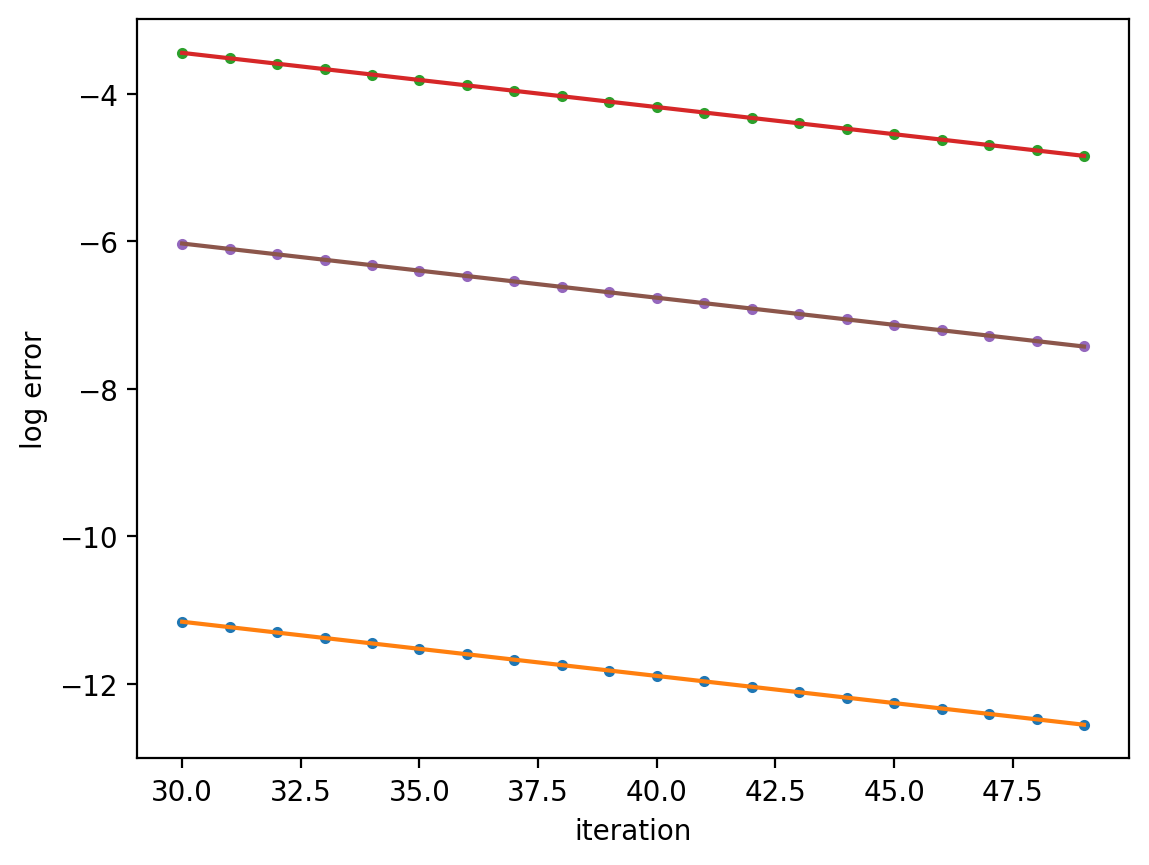

In [44]:
# Calculate convergence rate 
imin = 30
imax = 50
iN = imax-imin
y = np.concatenate(( np.log(np.abs(lambda_iter[imin:imax,0] - lambda_iter[-1,0])),
                     np.log(np.abs(lambda_iter[imin:imax,1] - lambda_iter[-1,1])),
                     np.log(np.abs(lambda_iter[imin:imax,2] - lambda_iter[-1,2])) ))
x = np.arange(imin,imax)

DM = np.concatenate(( np.column_stack(( x**0,  0*x,  0*x, -x)),
                      np.column_stack((  0*x, x**0,  0*x, -x)),
                      np.column_stack((  0*x,  0*x, x**0, -x)) ))
coeff = np.linalg.lstsq(DM, y, rcond=None)[0]
fit = DM@coeff

for i in range(3):
    plt.plot(x,y[i*iN:(i+1)*iN],'.')
    plt.plot(x,fit[i*iN:(i+1)*iN])
plt.xlabel('iteration')
plt.ylabel('log error')

error = np.sqrt(np.sum((fit - y)**2))
print('RMS error = %f'%error)

rate = coeff[-1]
print(f'Convergence rate = {rate:.5f}')

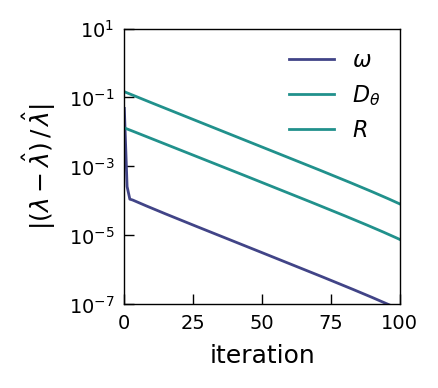

In [46]:
# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.8
right_margin = 0.2
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
ax.semilogy(np.abs((lambda_iter[:,0]-lambda_map3[0])/lambda_map3[0]), label=r'$\omega$', color=cmap(0.2), lw=1)
ax.semilogy(np.abs((lambda_iter[:,1]-lambda_map3[1])/lambda_map3[1]), label=r'$D_\theta$', color=cmap(0.5), lw=1)
ax.semilogy(np.abs((lambda_iter[:,2]-lambda_map3[2])/lambda_map3[2]), label=r'$R$', color=cmap(0.5), lw=1)
# ax.plot(x+jmin, 0.3*np.exp(fit[:jN])/np.abs(lambda_hat[0]), 'k--', lw=1)

# Set axis labels with font size 9 pt
ax.set_xlabel(r'iteration', fontsize=9)
ax.set_ylabel(r'$| (\lambda - \hat{\lambda}) \, / \, \hat{\lambda}|$', fontsize=9)
plt.ylim(1e-7,10)
plt.xlim(0,100)

# Create legend (frame turned off)
ax.legend(frameon=False, fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SyntheticPhaseConvergence.pdf')

## Uncertainty Estimate

### Prior Information Matrix, $\mathcal{I}_{\text{prior}}=-\nabla_\lambda^2 \ln p(\lambda)\rvert_{\hat{\lambda}}$


In [47]:
I_prior = SPLM.prior_information(lambda_map2, priors, param_type="log")
print(I_prior)

[[1.         0.         0.        ]
 [0.         7.44639608 0.        ]
 [0.         0.         5.10777546]]


### Complete-data Information, $\mathcal{I}_{\text{comp}} = -\mathbb{E}[\nabla_\lambda^2 \ell_c(\lambda;\theta,y)\mid y, \hat{\lambda}]$ 

In [48]:
statistics = SPLM.smoothing_statistics(lambda_map2, data, priors, param_type="log")
I_comp = SPLM.complete_data_information(lambda_map2, statistics, param_type="log")
print(I_comp)

[[1.85973742e+02 5.00291829e-02 0.00000000e+00]
 [5.00291829e-02 4.93053205e+02 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 4.95892049e+02]]


### Missing Information, $\mathcal{I}_{\text{miss}} = \mathrm{Cov}(\nabla_\lambda \ell_c(\lambda; \theta, y)\mid y, \hat{\lambda})$ 

In [49]:
I_miss = SPLM.missing_information(lambda_map2, statistics, priors, param_type="log")
print(I_miss)

[[ 1.24685366e+00 -2.59649990e-02  9.05731525e-03]
 [-2.59649990e-02  4.63005707e+02 -2.81744925e+01]
 [ 9.05731525e-03 -2.81744925e+01  9.33425991e+01]]


### Posterior Coviarance

In [50]:
%time 

res = SPLM.posterior_information(lambda_map2, data, priors, param_type="log")
print(np.linalg.norm(res['I_prior'] - I_prior))
print(np.linalg.norm(res['I_comp'] - I_comp))
print(np.linalg.norm(res['I_miss'] - I_miss))

CPU times: user 3 μs, sys: 1e+03 ns, total: 4 μs
Wall time: 6.2 μs
0.0
0.0
0.0


In [51]:
lambda_cov2 = np.linalg.inv(I_prior + I_comp - I_miss)
print(np.linalg.norm(res['cov'] - lambda_cov2))

0.0


Compare to numerical result

In [52]:
print(np.linalg.norm(res['cov'] - lambda_cov))
print(np.linalg.eigvals(lambda_cov))
print(np.linalg.eigvals(res['cov']))

5.620470917680562e-06
[0.00538069 0.02827489 0.00244013]
[0.00538425 0.02827921 0.00244028]


### EM Convergence rate

In [53]:
rho = np.max(np.linalg.eigvals(I_miss@np.linalg.inv(I_prior + I_comp)))
print(res['rho'] - rho)
print(f'Estimate of convergence rate = {-np.log(rho):.5f}')
print(f'EM convergence rate = {rate:.5f}')

0.0
Estimate of convergence rate = 0.07327
EM convergence rate = 0.07349
